# Aprendizaje de Simbolo

Se aprende un simbolo escalar real $a_\theta:\mathbb{Z}^n\to\mathbb{R}$ con una MLP: capas ocultas con
`Tanh` y una unica salida real.

**Función de perdida**

$$\mathcal{L} = \lambda_{\text{traj}}\,\mathcal{L}_{\text{traj}} + \lambda_{\text{par}}\,\mathcal{L}_{\text{par}} + \lambda_{\text{class}}\,\mathcal{L}_{\text{class}}$$

- **Trayectoria:** $\mathcal{L}_{\text{traj}} = \mathbb{E}\big[|e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k}) - \hat u_{\text{ref}}(\mathbf{k},t)|^2\big]$
- **Parabolicidad (Def. 2.3):** $\mathcal{L}_{\text{par}} = \mathbb{E}\big[\max\big(0,\ |(a_\theta(\mathbf{k})+\lambda)^{-1}| - \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}\big)^2\big]$,
  sobre $\mathrm{Re}(\lambda)\ge 0$, $|(\mathbf{k},\lambda)|\ge\omega$.
- **Clase de simbolo $S^{m,\rho}$:**
  $\mathcal{L}_{\text{class}} = \mathbb{E}_{\mathbf{k}}\Big[\frac{1}{|A_\rho|}\sum_{\alpha\in A_\rho}\max\big(0,\ \langle\mathbf{k}\rangle^{|\alpha|-m}\,|\Delta^\alpha_k a_\theta(\mathbf{k})| - C_\alpha\big)^2\Big]$,
  con $A_\rho=\{\alpha\in\mathbb{N}_0^n : |\alpha|\le\rho\}$, $\langle\mathbf{k}\rangle=(1+|\mathbf{k}|^2)^{1/2}$ y
  $\Delta_{k_j}a(\mathbf{k})=a(\mathbf{k}+e_j)-a(\mathbf{k})$. 
Como referencia se usa el simbolo del calor $a(\mathbf{k}) = |\mathbf{k}|^2$ en $\mathbb{T}^2$
($n=2$, $m=2$, $\rho=n+1=3$).

# Setup
- **Datos:** $10^5$ muestras. La particion es **por $\mathbf{k}$** (80% / 20% de los $k$
  unicos): todas las muestras de un mismo $k$ caen en el mismo conjunto, asi que los $k$ de
  validacion nunca se ven en entrenamiento.
- **$\kappa$ como hiperparametro**
- **Arquitecturas probadas:** barrido de $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas.
- **Regularizacion:** dropout $0.2$ en las capas ocultas interiores (se compara `none` frente a
  `middle`), weight decay $\{0,\ 10^{-4}\}$ en las `Linear` ocultas interiores, y **early stopping**
  sobre la perdida total de validacion.

In [26]:
import sys
sys.path.insert(0, "../src")  # ruta para las clases

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.ParabolicityVerifier import ParabolicityVerifier
from parabolic_symbol.SymbolClassVerifier import SymbolClassVerifier
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.mlp_symbol import MLPSymbol, default_device
from parabolic_symbol.data import (
    k_grid,
    make_trajectory_data,
    phase_grid,
    split_trajectory_data,
)
from parabolic_symbol.evaluation import symbol_report, trajectory_report
from parabolic_symbol.sweep import best_run, max_ratio_on, run_sweep, sweep_table
from parabolic_symbol.training import TrainingConfig

np.set_printoptions(precision=4, suppress=True)

device = default_device()
dtype = torch.float32 if device.type == "cuda" else torch.float64
print(f"device = {device}  |  dtype = {dtype}")

device = cuda  |  dtype = torch.float32


## 1. Datos de referencia

$\hat u_{\text{ref}}(\mathbf{k},t) = e^{-t|\mathbf{k}|^2}\hat u_0(\mathbf{k})$, con $|k_i|\le k_{\max}$.
El tiempo se muestrea log-uniforme.

In [27]:
n = 2
k_max = 12
reference = HeatSymbol(n=n)

data = make_trajectory_data(
    reference, k_max=k_max, n_samples=100000, t_min=1e-3, t_max=1.0, seed=0
)
# Particion por k: cada k unico va entero a entrenamiento o a validacion.
train_data, val_data = split_trajectory_data(data, val_fraction=0.2, seed=0)

k_train_values = np.unique(train_data["k"].numpy(), axis=0)
k_val_values = np.unique(val_data["k"].numpy(), axis=0)

print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras / {len(k_train_values)} k unicos")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras / {len(k_val_values)} k unicos")

entrenamiento: 79,836 muestras / 500 k unicos
validacion:    20,164 muestras / 125 k unicos


## 2. Malla de $\kappa$ y constantes $C_\alpha$

Se estima $\hat\kappa$ del simbolo de referencia con el verificador y se construye una malla alrededor.
Las constantes $C_\alpha$ de $\mathcal{L}_{\text{class}}$ se estiman igual, del simbolo analitico en la
ventana de entrenamiento y con un margen: asi la cota que se le exige a la red la cumple la respuesta
correcta, y el termino no la aleja de $|\mathbf{k}|^2$.

In [28]:
omega = 1.0
k_values = list(k_grid(n, k_max))
lam_values = [complex(re, im) for re in (0, 1, 5, 10, 25, 50) for im in (-50, -10, -2, 0, 2, 10, 50)]

kappa_ref = ParabolicityVerifier(reference).estimate_kappa(k_values, lam_values, omega=omega)
kappas = [round(factor * kappa_ref, 3) for factor in (0.75, 1.0, 1.25, 1.5, 2.0)]

# Constantes C_alpha de la Def. 2.1 para L_class, del simbolo analitico en |k_i| <= k_max
class_margin = 1.5
verifier_clase = SymbolClassVerifier(reference)
C_ref = {alpha: verifier_clase.estimate_constant(alpha, k_max)
         for alpha in verifier_clase.multi_indices()}
C_piso = min(c for c in C_ref.values() if c > 0)
class_C = {alpha: class_margin * max(c, C_piso) for alpha, c in C_ref.items()}

print(f"kappa_hat referencia = {kappa_ref:.4f}")
print(f"malla de kappa       = {kappas}")
print(f"C_alpha referencia   = { {str(a): round(c, 3) for a, c in C_ref.items()} }")
print(f"class_C (x{class_margin}, piso {C_piso:.3f}) = { {str(a): round(c, 3) for a, c in class_C.items()} }")

kappa_hat referencia = 2.0000
malla de kappa       = [1.5, 2.0, 2.5, 3.0, 4.0]
C_alpha referencia   = {'(0, 0)': 0.997, '(0, 1)': 2.236, '(1, 0)': 2.236, '(0, 2)': 2.0, '(1, 1)': 0.0, '(2, 0)': 2.0, '(0, 3)': 0.0, '(1, 2)': 0.0, '(2, 1)': 0.0, '(3, 0)': 0.0}
class_C (x1.5, piso 0.997) = {'(0, 0)': 1.495, '(0, 1)': 3.354, '(1, 0)': 3.354, '(0, 2)': 3.0, '(1, 1)': 1.495, '(2, 0)': 3.0, '(0, 3)': 1.495, '(1, 2)': 1.495, '(2, 1)': 1.495, '(3, 0)': 1.495}


## 3. Barrido de hiperparametros

Ejes: $5$ valores de $\kappa$ $\times$ $3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del
dropout $\times$ $2$ weight decays $=$ **150 entrenamientos**.

- **Dropout:** tasa **fija** de $0.2$; lo que se compara es *donde* se aplica, `none` frente a `middle`
  (capas ocultas interiores, excluyendo la primera y la ultima). Con $2$ capas ocultas `middle` no deja
  ninguna capa, asi que equivale a `none` y esa corrida no se repite.
- **Weight decay:** $\{0,\ 10^{-4}\}$, solo sobre las `Linear` ocultas interiores.

Cada corrida se marca como **cumple** si el peor ratio
$|(a_\theta+\lambda)^{-1}|\,/\,\kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}$
sobre la rejilla fija de comprobacion es $\le 1$. Esa rejilla es independiente de los puntos
muestreados asi que la decision no esta contaminada por el entrenamiento.

In [29]:
check_phase = phase_grid(n, k_max, lam_values, device=device, dtype=dtype)

base_config = TrainingConfig(
    epochs=300,
    batch_size=1024,
    lr=1e-3,
    lr_final=1e-5,
    omega=omega,
    lambda_trajectory=1.0,
    lambda_parabolicity=1.0,
    lambda_class=1.0,
    class_C=class_C,    # C_alpha de la referencia con margen (celda 6)
    k_max=k_max,
    lam_min=1e-2,
    lam_max=1e2,
    grad_clip=1.0,
    patience=30,        # early stopping
    n_phase_eval=8192,  # puntos (k, lambda) fijos para las metricas por epoca
    log_every=0,        # el barrido ya imprime una linea por corrida
    seed=0,
)

runs = run_sweep(
    train_data,
    val_data,
    n=n,
    m=2.0,
    kappas=kappas,
    depths=[2, 3, 4],
    widths=[32, 64, 128],
    base_config=base_config,
    check_phase=check_phase,
    dropout=0.2,
    dropout_layers=["none", "middle"],
    weight_decays=[0.0, 1e-4],
    input_scale=k_max,
    output_scale=k_max**2,
    device=device,
    dtype=dtype,
)

[  1/150] kappa= 1.500 2x32  drop[-] wd=0e+00 | NO cumple rel_l2=0.0524 | 163.7s
[  2/150] kappa= 1.500 2x32  drop[-] wd=1e-04 | NO cumple rel_l2=0.0527 | 164.7s
[  3/150] kappa= 1.500 2x64  drop[-] wd=0e+00 | NO cumple rel_l2=0.0487 | 158.8s
[  4/150] kappa= 1.500 2x64  drop[-] wd=1e-04 | NO cumple rel_l2=0.0479 | 162.3s
[  5/150] kappa= 1.500 2x128 drop[-] wd=0e+00 | NO cumple rel_l2=0.0354 | 165.1s
[  6/150] kappa= 1.500 2x128 drop[-] wd=1e-04 | NO cumple rel_l2=0.0361 | 167.4s
[  7/150] kappa= 1.500 3x32  drop[-] wd=0e+00 | NO cumple rel_l2=0.0473 | 174.2s
[  8/150] kappa= 1.500 3x32  drop[-] wd=1e-04 | NO cumple rel_l2=0.0467 | 173.1s
[  9/150] kappa= 1.500 3x32  drop[1] wd=0e+00 | NO cumple rel_l2=0.7554 |  19.1s
[ 10/150] kappa= 1.500 3x32  drop[1] wd=1e-04 | NO cumple rel_l2=0.7568 |  19.6s
[ 11/150] kappa= 1.500 3x64  drop[-] wd=0e+00 | NO cumple rel_l2=0.0481 | 173.8s
[ 12/150] kappa= 1.500 3x64  drop[-] wd=1e-04 | NO cumple rel_l2=0.0463 | 172.1s
[ 13/150] kappa= 1.500 3x64 

## 4. Resultados del barrido

In [30]:
table = sweep_table(runs)

# Solo las corridas que cumplen la cota en la rejilla de seleccion, de mejor a peor:
COLS = ["kappa", "capas", "ancho", "dropout", "weight_decay",
        "val_rel_l2", "val_total", "max_ratio"]

cumplen = table[table["cumple"]]
if cumplen.empty:
    print(f"Ninguna de las {len(table)} corridas cumple la cota en la rejilla de seleccion,")
    print(f"para ningun kappa de la malla: {sorted(table['kappa'].unique().tolist())}.")
    print(f"Mejor max_ratio del barrido = {table['max_ratio'].min():.3f} (hace falta <= 1).")
    print("Ver el resumen por kappa de la celda siguiente; toca ampliar la malla de kappa,")
    print("las arquitecturas o el presupuesto de entrenamiento.")
else:
    display(cumplen[COLS].sort_values(["kappa", "val_rel_l2"]).reset_index(drop=True))


,kappa,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,max_ratio
0,2.0,2,64,OFF,0.0001,0.047043,0.000461,0.989158
1,2.0,2,64,OFF,0.0000,0.049267,0.000506,0.983242
2,2.0,2,32,OFF,0.0001,0.051022,0.000543,0.995322
3,2.5,2,128,OFF,0.0001,0.035884,0.000268,0.812342
4,2.5,4,64,OFF,0.0001,0.040451,0.000341,0.846605
5,2.5,4,64,OFF,0.0000,0.042276,0.000373,0.765571
6,2.5,3,32,OFF,0.0001,0.047230,0.000465,0.822848
7,2.5,2,32,OFF,0.0001,0.048825,0.000497,0.839153
8,2.5,2,64,OFF,0.0000,0.049191,0.000504,0.813680
9,2.5,2,32,OFF,0.0000,0.049348,0.000508,0.782754


In [31]:
# Por kappa, y por configuracion de regularizacion (dropout / weight decay).
resumen = table.groupby("kappa").agg(
    cumplen=("cumple", "sum"),
    corridas=("cumple", "count"),
    mejor_max_ratio=("max_ratio", "min"),
    mejor_val_rel_l2=("val_rel_l2", "min"),
    mejor_val_total=("val_total", "min"),
)
display(resumen)

for eje in ("dropout", "weight_decay"):
    if table[eje].nunique() > 1:
        display(
            table[table["cumple"]].groupby(eje).agg(
                cumplen=("cumple", "size"),
                kappa_min=("kappa", "min"),
                mejor_val_rel_l2=("val_rel_l2", "min"),
                mejor_val_total=("val_total", "min"),
                peor_ratio=("val_par_max_ratio", "min"),
            )
        )

,cumplen,corridas,mejor_max_ratio,mejor_val_rel_l2,mejor_val_total
kappa,,,,,
1.5,0,30,1.153584,0.035360,0.000281
2.0,3,30,0.983242,0.035161,0.000258
2.5,10,30,0.765571,0.035884,0.000268
3.0,8,30,0.666563,0.036630,0.000280
4.0,12,30,0.496685,0.044427,0.000411


,cumplen,kappa_min,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,,
OFF,33,2.0,0.035884,0.000268,0.493858


,cumplen,kappa_min,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,,
0.0000,16,2.0,0.036630,0.000280,0.494593
0.0001,17,2.0,0.035884,0.000268,0.493858


### Seleccion: la mejor aproximacion entre las que cumplen

Toda corrida marcada como **cumple** satisface la Def. 2.3 con su propio $\kappa$, asi que $\kappa$ no
ordena la seleccion: entre todas las que cumplen se toma la de **mejor error relativo de validacion**,
sea cual sea su $\kappa$.


In [32]:
best = best_run(runs)
if best is None:
    raise RuntimeError("ninguna corrida del barrido cumple la cota")

symbol = best.symbol
kappa_min_cumple = min(run.kappa for run in runs if run.satisfied)
print(f"kappa de la corrida elegida = {best.kappa:.4f}   "
      f"(el menor kappa que cumple en el barrido fue {kappa_min_cumple:.4f})")

# Kappa que realmente exhibe el simbolo aprendido, medido sobre la REJILLA DE
# CERTIFICACION (seccion 7): independiente de la malla de kappa y de la rejilla
# con la que se decidio que corridas cumplen. Junto a kappa_ref (celda 6) dice
# cuanto se alejo el simbolo aprendido del simbolo verdadero.
cert_radii = np.logspace(-2, 3, 25)                    # |lambda| en [1e-2, 1e3]
cert_angles = np.linspace(-np.pi / 2, np.pi / 2, 25)   # incluye la frontera Re(lambda) = 0
cert_lam = (cert_radii[:, None] * np.exp(1j * cert_angles)).ravel()
cert_k_max = 3 * k_max

kappa_learned = ParabolicityVerifier(symbol).estimate_kappa(
    list(k_grid(n, cert_k_max)), cert_lam, omega=omega
)
print(f"kappa_hat aprendido         = {kappa_learned:.4f}   (certificacion, |k_i| <= {cert_k_max})")
print(f"kappa_hat referencia        = {kappa_ref:.4f}   (simbolo analitico, celda 6)")

print(f"arquitectura elegida    = {best.n_layers} capas x {best.width} neuronas")
print(f"dropout                 = {best.dropout_desc}")
print(f"weight decay            = {best.weight_decay:g}  (Linear ocultas interiores)")
print(f"early stopping          = mejor epoca {best.best_epoch} de {best.epochs_run} corridas")
print(f"max ratio (seleccion)   = {best.max_ratio:.4f}  (<= 1 en la rejilla de seleccion)")
print()
print("metricas de validacion en la mejor epoca:")
print(f"  total             = {best.val_total:.4e}")
print(f"  trayectoria       = {best.val_trajectory:.4e}")
print(f"  parabolicidad     = {best.val_parabolicity:.4e}   (0 => ningun punto viola la cota)")
print(f"  rel_l2            = {best.val_rel_l2:.4f}")
print(f"  peor ratio        = {best.val_par_max_ratio:.4f}")
print(f"  puntos con >1     = {100 * best.val_par_violation:.2f}%")


kappa de la corrida elegida = 2.5000   (el menor kappa que cumple en el barrido fue 2.0000)
kappa_hat aprendido         = 6.9199   (certificacion, |k_i| <= 36)
kappa_hat referencia        = 2.0000   (simbolo analitico, celda 6)
arquitectura elegida    = 2 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0.0001  (Linear ocultas interiores)
early stopping          = mejor epoca 291 de 300 corridas
max ratio (seleccion)   = 0.8123  (<= 1 en la rejilla de seleccion)

metricas de validacion en la mejor epoca:
  total             = 2.6838e-04
  trayectoria       = 2.6838e-04
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  rel_l2            = 0.0359
  peor ratio        = 0.8264
  puntos con >1     = 0.00%


### Metricas del modelo seleccionado

Se presentan dos reportes distintos:

- **Trayectoria** $\hat u(\mathbf{k},t) = e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k})$, sobre las muestras
  de entrenamiento y de validacion.
- **Simbolo** $a_\theta(\mathbf{k})$ frente a $|\mathbf{k}|^2$, por separado sobre los $k$ de entrenamiento y
  los $k$ de validacion (estos ultimos la red nunca los vio).

Se reportan RMSE, MAE y $R^2$.

In [33]:
traj = {"entrenamiento": trajectory_report(symbol, train_data),
        "validacion": trajectory_report(symbol, val_data)}
n_muestras = {split: int(rep.pop("n")) for split, rep in traj.items()}

print("TRAYECTORIA  -- residuo complejo |u_pred - u_ref|")
print(f"  muestras: {n_muestras['entrenamiento']:,} entrenamiento / {n_muestras['validacion']:,} validacion")
display(pd.DataFrame(traj))

# El split es por k, asi que el simbolo se reporta por separado sobre los k de
# entrenamiento y sobre los k de validacion, que la red nunca vio.
sym = {"entrenamiento": symbol_report(symbol, reference, k_train_values),
       "validacion": symbol_report(symbol, reference, k_val_values)}
n_k = {split: int(rep.pop("n")) for split, rep in sym.items()}

print("SIMBOLO  -- a_theta(k) vs |k|^2")
print(f"  k unicos: {n_k['entrenamiento']} de entrenamiento / {n_k['validacion']} de validacion")
display(pd.DataFrame(sym))

print("PARABOLICIDAD")
print(f"  kappa usada             = {best.kappa:.4f}")
print(f"  peor ratio (seleccion)  = {best.max_ratio:.4f}   (rejilla de seleccion, no certifica)")
print(f"  hinge^2 de validacion   = {best.val_parabolicity:.4e}")


TRAYECTORIA  -- residuo complejo |u_pred - u_ref|
  muestras: 79,836 entrenamiento / 20,164 validacion


,entrenamiento,validacion
mse,0.000312,0.000268
rmse,0.017676,0.016382
mae,0.008899,0.008025
max_error,0.220882,0.207407
rel_l2,0.037442,0.035884
r2,0.998598,0.998712


SIMBOLO  -- a_theta(k) vs |k|^2
  k unicos: 500 de entrenamiento / 125 de validacion


,entrenamiento,validacion
mse,231.057990,189.350969
rmse,15.200592,13.760486
mae,8.731259,7.870686
max_error,71.632141,59.499466
rel_l2,0.123352,0.112858


PARABOLICIDAD
  kappa usada             = 2.5000
  peor ratio (seleccion)  = 0.8123   (rejilla de seleccion, no certifica)
  hinge^2 de validacion   = 0.0000e+00


## 5. Curvas de entrenamiento

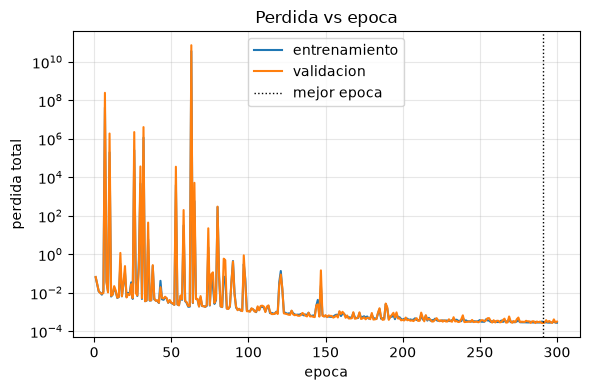

In [34]:
history = best.result.history
epochs = np.arange(1, len(history["train"]["total"]) + 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(epochs, history["train"]["total"], label="entrenamiento")
ax.semilogy(epochs, history["val"]["total"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel("perdida total")
ax.set_title("Perdida vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


La perdida total graficada es la que registra `evaluate_split`: trayectoria + parabolicidad. **No incluye
$\mathcal{L}_{\text{class}}$** aunque $\lambda_{\text{class}}>0$, y el early stopping usa esa misma cantidad.

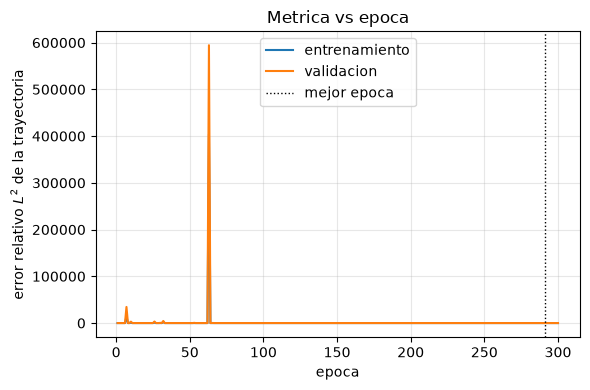

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs, history["train"]["rel_l2"], label="entrenamiento")
ax.plot(epochs, history["val"]["rel_l2"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel(r"error relativo $L^2$ de la trayectoria")
ax.set_title("Metrica vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Nota:** La linea punteada vertical marca la epoca cuyos pesos restauro el early stopping.

## 6. Simbolo aprendido vs. referencia

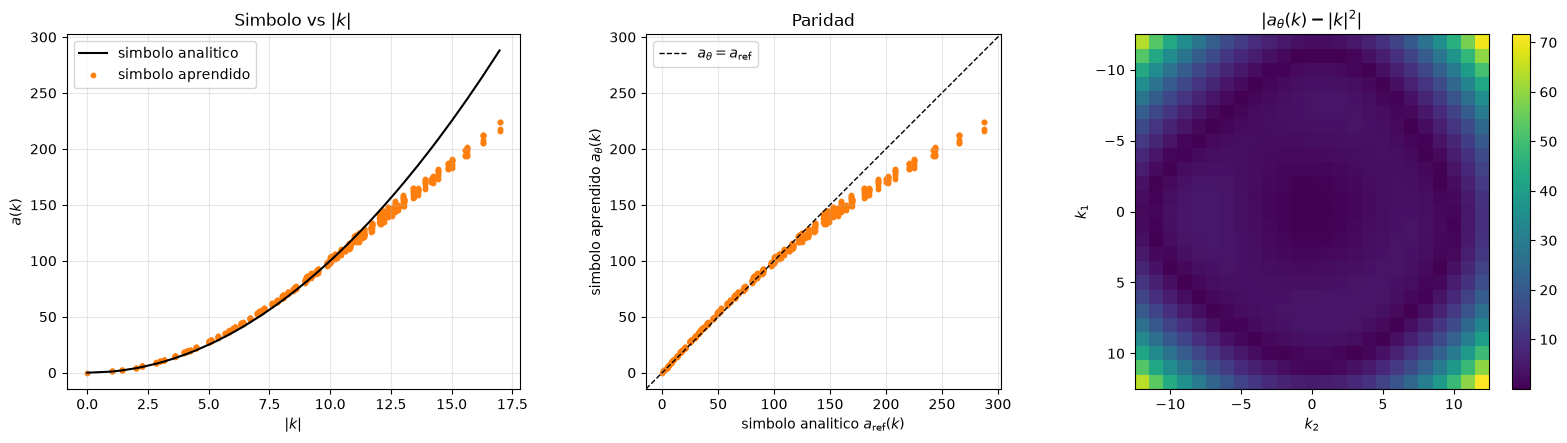

error relativo medio = 0.075, maximo = 0.249


In [36]:
k_arr = np.array(k_values)
a_true = np.array([reference(k)[0, 0] for k in k_values])
a_learn = symbol.evaluate_batch(k_arr)   # un solo forward por lotes
norm_k2 = np.sum(k_arr**2, axis=1)
norm_k = np.linalg.norm(k_arr, axis=1)

# Los dos simbolos son reales; np.real descarta la parte imaginaria nula que
# arrastra la interfaz compleja de Symbol.
a_ref_r, a_theta_r = np.real(a_true), np.real(a_learn)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) La curva del simbolo. Para el calor, a(k) = |k|^2 es una parabola en |k|.
order = np.argsort(norm_k)
axes[0].plot(norm_k[order], a_ref_r[order], "k-", lw=1.5, label="simbolo analitico")
axes[0].scatter(norm_k, a_theta_r, s=10, color="C1", label="simbolo aprendido")
axes[0].set_xlabel(r"$|k|$")
axes[0].set_ylabel(r"$a(k)$")
axes[0].set_title(r"Simbolo vs $|k|$")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Paridad: cada k es un punto; sobre la diagonal significa que a_theta acerto.
lo = min(a_ref_r.min(), a_theta_r.min())
hi = max(a_ref_r.max(), a_theta_r.max())
pad = 0.05 * (hi - lo)
lims = [lo - pad, hi + pad]
axes[1].plot(lims, lims, "k--", lw=1, label=r"$a_\theta = a_{\text{ref}}$")
axes[1].scatter(a_ref_r, a_theta_r, s=10, color="C1")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_aspect("equal")
axes[1].set_xlabel(r"simbolo analitico $a_{\mathrm{ref}}(k)$")
axes[1].set_ylabel(r"simbolo aprendido $a_\theta(k)$")
axes[1].set_title("Paridad")
axes[1].legend()
axes[1].grid(alpha=0.3)

# (c) Error absoluto sobre la rejilla (k1, k2).
im = axes[2].imshow(
    np.abs(a_learn - a_true).reshape(2 * k_max + 1, 2 * k_max + 1),
    extent=[-k_max - 0.5, k_max + 0.5, k_max + 0.5, -k_max - 0.5],
)
axes[2].set_title(r"$|a_\theta(k) - |k|^2|$")
axes[2].set_xlabel(r"$k_2$")
axes[2].set_ylabel(r"$k_1$")
fig.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()

rel = np.abs(a_learn - a_true) / np.maximum(norm_k2, 1)
print(f"error relativo medio = {rel.mean():.3f}, maximo = {rel.max():.3f}")


Para $|\mathbf{k}|$ grande $e^{-t|\mathbf{k}|^2}\approx 0$ en casi todo el rango de $t$, asi que la perdida de
trayectoria da poca informacion alli y el error es mayor.

## 7. Certificacion de Parabolicidad

La rejilla de seleccion (`lam_values` / `check_phase`) ya se uso para estimar $\hat\kappa$ y para
decidir que corridas cumplen, asi que no puede ademas certificar el resultado. Aqui se usa una
rejilla **independiente**, que solo se evalua sobre el modelo ya elegido (nunca durante la
seleccion); se define en la celda de seleccion, que ya la usa para medir $\hat\kappa$ del
simbolo aprendido:

- $k$ en $|k_i|\le 3k_{\max}$, tres veces la ventana de entrenamiento;
- $|\lambda|$ log-espaciado en $[10^{-2},10^{3}]$ con $25$ angulos en $[-\pi/2,\pi/2]$,
  extremos incluidos (la frontera $\mathrm{Re}(\lambda)=0$).


In [37]:
# Rejilla de CERTIFICACION (cert_lam, cert_k_max): definida en la celda de seleccion,
# independiente de la rejilla con la que se decidio que corridas cumplen.


def cert_max_ratio(k_window, chunk=200_000):
    """Peor ratio sobre (|k_i| <= k_window) x cert_lam, por trozos para no llenar memoria."""
    kk, ll = phase_grid(n, k_window, cert_lam, device=device, dtype=dtype)
    return max(
        max_ratio_on(symbol, (kk[i : i + chunk], ll[i : i + chunk]), omega, best.kappa)
        for i in range(0, kk.shape[0], chunk)
    )


n_k_cert = len(k_grid(n, cert_k_max))
max_ratio = cert_max_ratio(cert_k_max)

print(f"{symbol!r}")
print(f"rejilla de certificacion: {n_k_cert:,} k (|k_i| <= {cert_k_max}) x "
      f"{len(cert_lam)} lambda = {n_k_cert * len(cert_lam):,} puntos")
print(f"kappa usada = {best.kappa:.4f}")
print(f"max ratio   = {max_ratio:.4f}   (<= 1 => la cota se cumple)")
print(f"cumple      = {max_ratio <= 1.0}")
print(f"kappa minimo que certificaria esta rejilla = {best.kappa * max_ratio:.4f}")


MLPSymbol(hidden=(128, 128), sin dropout)(n=2, m=2.0, rho=3, dim=1)
rejilla de certificacion: 5,329 k (|k_i| <= 36) x 625 lambda = 3,330,625 puntos
kappa usada = 2.5000
max ratio   = 2.7679   (<= 1 => la cota se cumple)
cumple      = False
kappa minimo que certificaria esta rejilla = 6.9199


In [38]:
# Hasta donde alcanza: peor ratio por ventana de k, con la misma rejilla de lambda.
# La parabolicidad solo puede esperarse dentro de la ventana muestreada.
for window in (k_max, 2 * k_max, cert_k_max):
    ratio = cert_max_ratio(window)
    donde = "dentro" if window <= k_max else "fuera "
    print(f"|k_i| <= {window:3d} ({donde} de la ventana de entrenamiento): "
          f"max ratio = {ratio:.4f} -> {'cumple' if ratio <= 1.0 else 'NO cumple'}")


|k_i| <=  12 (dentro de la ventana de entrenamiento): max ratio = 0.8257 -> cumple
|k_i| <=  24 (fuera  de la ventana de entrenamiento): max ratio = 1.3481 -> NO cumple
|k_i| <=  36 (fuera  de la ventana de entrenamiento): max ratio = 2.7679 -> NO cumple


## 8. Clase del simbolo: $S^{m,\rho}$

La Def. 2.1 pide que, para todo multiindice $\alpha$ con $|\alpha|\le\rho$, exista $C_\alpha\ge 0$ con

$$\|\Delta^\alpha_k a(\mathbf{k})\|_{L(E)} \le C_\alpha\,\langle \mathbf{k}\rangle^{\,m-|\alpha|},
\qquad \langle \mathbf{k}\rangle=(1+|\mathbf{k}|^2)^{1/2},$$

con $\Delta_{k_j}a(\mathbf{k}) = a(\mathbf{k}+e_j)-a(\mathbf{k})$ (diferencia hacia adelante).
Se usa $\rho = $ `symbol.rho`.

`SymbolClassVerifier` estima $\hat C_\alpha(K)$ sobre ventanas crecientes $\{|k_i|\le K\}$ y mide la
pendiente log-log por capas de radio. **Es evidencia en una ventana finita, no una prueba:** la
definicion cuantifica sobre todo $\mathbb{Z}^n$, y la red solo esta restringida donde se la entreno.

La misma desigualdad es la que penaliza $\mathcal{L}_{\text{class}}$ durante el entrenamiento, pero solo
en los $\mathbf{k}$ muestreados ($|k_i|\le k_{\max}$). Esta seccion mira ventanas mas grandes para ver si la
penalizacion se sostiene fuera de esa region.

In [39]:
class_k_maxs = (4, 8, 12, 2 * k_max)   # ventanas crecientes para ver si C_alpha se estabiliza
resultados_clase = SymbolClassVerifier(symbol).check(k_maxs=class_k_maxs)

clase = pd.DataFrame([
    {
        "alpha": str(r.alpha),
        "|alpha|": r.order,
        **{f"C_hat({K})": r.c_hat[K] for K in class_k_maxs},
        f"crecim.({class_k_maxs[-2]}->{class_k_maxs[-1]})": r.growth,
        "pendiente": r.slope,
        "m-|alpha|": r.slope_theoretical,
        "estable": r.stable,
        "consistente": r.consistent,
    }
    for r in resultados_clase
])
display(clase)

ok = int(clase["consistente"].sum())
print(f"consistentes: {ok} de {len(clase)} multiindices (rho = {symbol.rho}, m = {symbol.m})")
print(f"ventana explorada: |k_i| <= {class_k_maxs[-1]} (evidencia, no prueba sobre todo Z^n)")
print("pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta")

,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(24),crecim.(12->24),pendiente,m-|alpha|,estable,consistente
0,"(0, 0)",0,1.079401,1.085910,1.085910,1.085910,1.000000,0.794873,2.0,True,True
1,"(0, 1)",1,2.542087,2.542087,2.542087,2.542087,1.000000,-0.450514,1.0,True,True
2,"(1, 0)",1,2.534616,2.534616,2.534616,2.534616,1.000000,-0.818671,1.0,True,True
3,"(0, 2)",2,2.321139,2.321139,2.321139,2.321139,1.000000,-0.136777,0.0,True,True
4,"(1, 1)",2,0.295666,0.809837,1.169296,1.297409,1.109564,-0.810377,0.0,False,False
5,"(2, 0)",2,2.275108,2.275108,2.275108,2.275108,1.000000,0.297497,0.0,True,False
6,"(0, 3)",3,1.118676,1.523500,1.527966,10.923127,7.148802,-1.256286,-1.0,False,False
7,"(1, 2)",3,0.357041,0.970630,1.542093,2.866670,1.858947,-0.445230,-1.0,False,False
8,"(2, 1)",3,0.386712,0.979897,1.504465,3.997541,2.657119,0.348063,-1.0,False,False
9,"(3, 0)",3,1.101890,1.518623,1.518623,11.153188,7.344277,-0.714388,-1.0,False,False


consistentes: 4 de 10 multiindices (rho = 3, m = 2.0)
ventana explorada: |k_i| <= 24 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta
